For project 1, the SST-2 (Stanford Sentiment Treebank) dataset was chosen. This dataset contains a sentence and its corresponding label. Where the label describes this sentence as positive or negative.

In [16]:
import os
#if '/home/taravd/UVA/MscAI/Y1/NLP1/P1/NLP/Project1' == os.getcwd():
if os.path.basename(os.getcwd()) == "Project1":
    os.chdir("..")
print(os.getcwd())

import numpy as np
import Project1.experiment as experiment
import Project1.clslib as clslib
import Project1.analysis as analysis

C:\My documents\UvA\NLP\Projects\Project_1\git\NLP


In [17]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/sst2")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 872
    })
    test: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 1821
    })
})


The following loads a trained BPE tokeniser that we personally trained.

In [18]:
from tokenizers import Tokenizer

tokenizer = Tokenizer.from_file(
    f"Project1/results/bpe_8000.json"
)

output = tokenizer.encode(dataset['train']['sentence'][0])

print(output.tokens)

['h', 'ide', '▁new', '▁secret', 'ions', '▁from', '▁the', '▁parent', 'al', '▁un', 'its', '▁']


The following code sets up the cross validations split

In [19]:
my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["sentence"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

Below the token indicator feature representation space is copied from tutorial 1.

In [20]:
class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

Below the token Bag of Words feature representation space.

In [21]:
class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a vector of token counts"""
        unique_token_ids = self.tokenizer.encode(x).ids
        
        # A 0 vector with the same length as the vocabulary, then one count per occurrence
        vector = np.zeros(len(self))
        for token_id in unique_token_ids:
            vector[token_id] += 1
        return vector

Training the log linear model with an indicator encoder.

In [22]:
from collections import OrderedDict
my_classifiers = OrderedDict()

stanfordnlpsst2_outcome_space = clslib.NamedClasses([ 'negative', 'positive'])
token_indicator_encoder = TokenIndicator(tokenizer)

my_classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"Project1/results/logistic_indicator-enc/seed-{seed}"
    my_classifiers['logistic_indicator-enc'].append(
        experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=stanfordnlpsst2_outcome_space,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\U

Training the MLP with the indicator encoder.

In [23]:
my_classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"Project1/results/mlp_indicator-enc/seed-{seed}"
    my_classifiers['mlp_indicator-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=stanfordnlpsst2_outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-4, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 192.603 seconds
Dataloader done! Time taken: 16.970 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6000 | train acc: 0.6788 | val loss: 0.4797 | val acc: 0.7887
Epoch 02 | train loss: 0.4027 | train acc: 0.8426 | val loss: 0.3655 | val acc: 0.8506
Epoch 03 | train loss: 0.3220 | train acc: 0.8739 | val loss: 0.3230 | val acc: 0.8662
Epoch 04 | train loss: 0.2824 | train acc: 0.8871 | val loss: 0.3039 | val acc: 0.8724
Epoch 05 | train loss: 0.2582 | train acc: 0.8959 | val loss: 0.2919 | val acc: 0.8780
Epoch 06 | train loss: 0.2411 | train acc: 0.9032 | val loss: 0.2867 | val acc: 0.8804
Epoch 07 | train loss: 0.2276 | train acc: 0.9075 | val loss: 0.2822 | val acc: 0.8837
Epoch 08 | train loss: 0.2166 | train acc: 0.9126 | val loss: 0.2810 | val acc: 0.8867
Epoch 09 | train loss: 0.2068 | train acc: 0.9164 | val loss: 0.2803 | val acc: 0.8866
Epoch 10 | train loss: 0.1977 | train acc: 0.9198 | val loss: 0.2795 | val acc: 0.8898
Training done! Time taken: 105.335 seconds
Transforming documents...
Document transformation done! Time taken: 198.347 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6049 | train acc: 0.6751 | val loss: 0.4862 | val acc: 0.7938
Epoch 02 | train loss: 0.4020 | train acc: 0.8445 | val loss: 0.3750 | val acc: 0.8445
Epoch 03 | train loss: 0.3200 | train acc: 0.8773 | val loss: 0.3356 | val acc: 0.8555
Epoch 04 | train loss: 0.2802 | train acc: 0.8904 | val loss: 0.3179 | val acc: 0.8621
Epoch 05 | train loss: 0.2555 | train acc: 0.8991 | val loss: 0.3080 | val acc: 0.8682
Epoch 06 | train loss: 0.2386 | train acc: 0.9053 | val loss: 0.3021 | val acc: 0.8707
Epoch 07 | train loss: 0.2242 | train acc: 0.9113 | val loss: 0.2990 | val acc: 0.8729
Epoch 08 | train loss: 0.2131 | train acc: 0.9155 | val loss: 0.2975 | val acc: 0.8748
Epoch 09 | train loss: 0.2033 | train acc: 0.9193 | val loss: 0.2981 | val acc: 0.8751
Epoch 10 | train loss: 0.1939 | train acc: 0.9226 | val loss: 0.2977 | val acc: 0.8771
Training done! Time taken: 105.022 seconds
Transforming documents...
Document transformation done! Time taken: 207.363 seconds
Dat

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6011 | train acc: 0.6743 | val loss: 0.4803 | val acc: 0.8042
Epoch 02 | train loss: 0.3990 | train acc: 0.8448 | val loss: 0.3757 | val acc: 0.8520
Epoch 03 | train loss: 0.3173 | train acc: 0.8770 | val loss: 0.3396 | val acc: 0.8610
Epoch 04 | train loss: 0.2775 | train acc: 0.8899 | val loss: 0.3238 | val acc: 0.8674
Epoch 05 | train loss: 0.2523 | train acc: 0.8992 | val loss: 0.3152 | val acc: 0.8697
Epoch 06 | train loss: 0.2348 | train acc: 0.9057 | val loss: 0.3113 | val acc: 0.8715
Epoch 07 | train loss: 0.2213 | train acc: 0.9107 | val loss: 0.3086 | val acc: 0.8748
Epoch 08 | train loss: 0.2096 | train acc: 0.9157 | val loss: 0.3081 | val acc: 0.8765
Epoch 09 | train loss: 0.2001 | train acc: 0.9205 | val loss: 0.3073 | val acc: 0.8800
Epoch 10 | train loss: 0.1918 | train acc: 0.9236 | val loss: 0.3082 | val acc: 0.8804
Training done! Time taken: 111.365 seconds
Transforming documents...
Document transformation done! Time taken: 210.526 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6022 | train acc: 0.6834 | val loss: 0.4829 | val acc: 0.8060
Epoch 02 | train loss: 0.4025 | train acc: 0.8448 | val loss: 0.3702 | val acc: 0.8500
Epoch 03 | train loss: 0.3203 | train acc: 0.8759 | val loss: 0.3301 | val acc: 0.8624
Epoch 04 | train loss: 0.2810 | train acc: 0.8878 | val loss: 0.3116 | val acc: 0.8701
Epoch 05 | train loss: 0.2567 | train acc: 0.8970 | val loss: 0.3016 | val acc: 0.8716
Epoch 06 | train loss: 0.2392 | train acc: 0.9046 | val loss: 0.2955 | val acc: 0.8747
Epoch 07 | train loss: 0.2260 | train acc: 0.9084 | val loss: 0.2916 | val acc: 0.8779
Epoch 08 | train loss: 0.2148 | train acc: 0.9140 | val loss: 0.2895 | val acc: 0.8808
Epoch 09 | train loss: 0.2049 | train acc: 0.9168 | val loss: 0.2889 | val acc: 0.8830
Epoch 10 | train loss: 0.1961 | train acc: 0.9215 | val loss: 0.2885 | val acc: 0.8840
Training done! Time taken: 109.484 seconds


Training the log linear model with a BagOfWords encoder.

In [24]:
bag_of_words_encoder = BagOfWords(tokenizer)

my_classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"Project1/results/logistic_bow-enc/seed-{seed}"
    my_classifiers['logistic_bow-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=stanfordnlpsst2_outcome_space,
            encoder=bag_of_words_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\U

Training the MLP with the BagOfWords encoder.

In [25]:
my_classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds)
    run_folder = f"Project1/results/mlp_bow-enc/seed-{seed}"
    my_classifiers['mlp_bow-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=stanfordnlpsst2_outcome_space,
            encoder=bag_of_words_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128,
                'dropout': 0.1,
                'batch_size': 64,
                'learning_rate': 1e-4,
                'weight_decay': 1e-4,
                'num_epochs': 10,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 211.347 seconds
Dataloader done! Time taken: 26.049 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6067 | train acc: 0.6763 | val loss: 0.4863 | val acc: 0.7971
Epoch 02 | train loss: 0.4100 | train acc: 0.8400 | val loss: 0.3707 | val acc: 0.8498
Epoch 03 | train loss: 0.3275 | train acc: 0.8728 | val loss: 0.3275 | val acc: 0.8641
Epoch 04 | train loss: 0.2882 | train acc: 0.8863 | val loss: 0.3072 | val acc: 0.8723
Epoch 05 | train loss: 0.2634 | train acc: 0.8941 | val loss: 0.2965 | val acc: 0.8774
Epoch 06 | train loss: 0.2457 | train acc: 0.9009 | val loss: 0.2898 | val acc: 0.8812
Epoch 07 | train loss: 0.2323 | train acc: 0.9061 | val loss: 0.2853 | val acc: 0.8846
Epoch 08 | train loss: 0.2211 | train acc: 0.9104 | val loss: 0.2837 | val acc: 0.8850
Epoch 09 | train loss: 0.2113 | train acc: 0.9145 | val loss: 0.2826 | val acc: 0.8862
Epoch 10 | train loss: 0.2025 | train acc: 0.9179 | val loss: 0.2826 | val acc: 0.8865
Training done! Time taken: 103.512 seconds
Transforming documents...
Document transformation done! Time taken: 212.796 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6022 | train acc: 0.6803 | val loss: 0.4923 | val acc: 0.7830
Epoch 02 | train loss: 0.4064 | train acc: 0.8410 | val loss: 0.3793 | val acc: 0.8434
Epoch 03 | train loss: 0.3241 | train acc: 0.8750 | val loss: 0.3390 | val acc: 0.8569
Epoch 04 | train loss: 0.2833 | train acc: 0.8898 | val loss: 0.3202 | val acc: 0.8636
Epoch 05 | train loss: 0.2589 | train acc: 0.8973 | val loss: 0.3110 | val acc: 0.8683
Epoch 06 | train loss: 0.2406 | train acc: 0.9049 | val loss: 0.3055 | val acc: 0.8711
Epoch 07 | train loss: 0.2276 | train acc: 0.9100 | val loss: 0.3018 | val acc: 0.8722
Epoch 08 | train loss: 0.2161 | train acc: 0.9148 | val loss: 0.2996 | val acc: 0.8741
Epoch 09 | train loss: 0.2062 | train acc: 0.9178 | val loss: 0.2985 | val acc: 0.8751
Epoch 10 | train loss: 0.1970 | train acc: 0.9222 | val loss: 0.2985 | val acc: 0.8771
Training done! Time taken: 105.338 seconds
Transforming documents...
Document transformation done! Time taken: 215.237 seconds
Dat

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6067 | train acc: 0.6799 | val loss: 0.4871 | val acc: 0.8031
Epoch 02 | train loss: 0.4055 | train acc: 0.8422 | val loss: 0.3801 | val acc: 0.8464
Epoch 03 | train loss: 0.3221 | train acc: 0.8748 | val loss: 0.3426 | val acc: 0.8607
Epoch 04 | train loss: 0.2819 | train acc: 0.8886 | val loss: 0.3257 | val acc: 0.8659
Epoch 05 | train loss: 0.2564 | train acc: 0.8980 | val loss: 0.3181 | val acc: 0.8709
Epoch 06 | train loss: 0.2389 | train acc: 0.9042 | val loss: 0.3131 | val acc: 0.8731
Epoch 07 | train loss: 0.2250 | train acc: 0.9101 | val loss: 0.3109 | val acc: 0.8740
Epoch 08 | train loss: 0.2137 | train acc: 0.9139 | val loss: 0.3097 | val acc: 0.8765
Epoch 09 | train loss: 0.2040 | train acc: 0.9176 | val loss: 0.3102 | val acc: 0.8777
Epoch 10 | train loss: 0.1952 | train acc: 0.9210 | val loss: 0.3103 | val acc: 0.8791
Training done! Time taken: 103.752 seconds
Transforming documents...
Document transformation done! Time taken: 218.304 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6074 | train acc: 0.6762 | val loss: 0.4895 | val acc: 0.8016
Epoch 02 | train loss: 0.4082 | train acc: 0.8419 | val loss: 0.3733 | val acc: 0.8540
Epoch 03 | train loss: 0.3247 | train acc: 0.8744 | val loss: 0.3328 | val acc: 0.8644
Epoch 04 | train loss: 0.2846 | train acc: 0.8885 | val loss: 0.3138 | val acc: 0.8709
Epoch 05 | train loss: 0.2599 | train acc: 0.8970 | val loss: 0.3046 | val acc: 0.8726
Epoch 06 | train loss: 0.2424 | train acc: 0.9035 | val loss: 0.2970 | val acc: 0.8771
Epoch 07 | train loss: 0.2284 | train acc: 0.9086 | val loss: 0.2930 | val acc: 0.8776
Epoch 08 | train loss: 0.2176 | train acc: 0.9125 | val loss: 0.2921 | val acc: 0.8795
Epoch 09 | train loss: 0.2080 | train acc: 0.9166 | val loss: 0.2903 | val acc: 0.8810
Epoch 10 | train loss: 0.1985 | train acc: 0.9210 | val loss: 0.2905 | val acc: 0.8825
Training done! Time taken: 104.669 seconds


Results

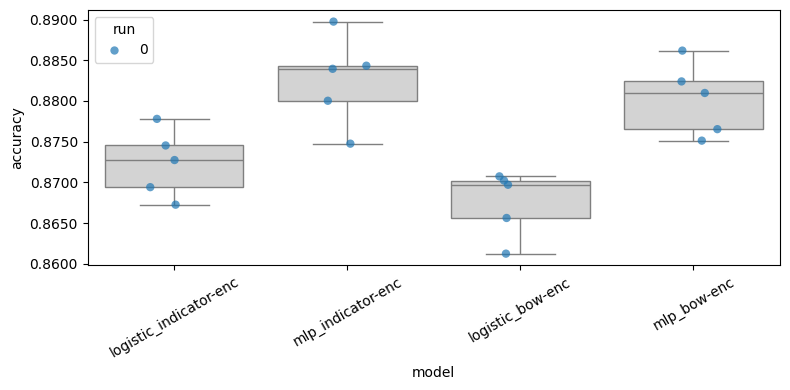

In [26]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [ ]:
import Project1.loglin as loglin
from sklearn.metrics import classification_report

def report_all_folds(seed=0, split="validation", num_folds=num_folds):
    X = np.vstack([token_indicator_encoder(s) for s in dataset[split]["sentence"]])  # encode once
    y_true = dataset[split]["label"]

    for fold in range(num_folds):
        path = f"Project1/results/logistic_indicator-enc/seed-{seed}/fold-{fold}/model"
        model = loglin.load(path)
        y_pred = model.predict(X)

        print(f"=== seed {seed}, fold {fold} ===")
        print(classification_report(y_true, y_pred,
                                    target_names=stanfordnlpsst2_outcome_space.names))

report_all_folds()

=== seed 0, fold 0 ===
              precision    recall  f1-score   support

    negative       0.71      0.70      0.70       428
    positive       0.71      0.72      0.72       444

    accuracy                           0.71       872
   macro avg       0.71      0.71      0.71       872
weighted avg       0.71      0.71      0.71       872

=== seed 0, fold 1 ===
              precision    recall  f1-score   support

    negative       0.71      0.69      0.70       428
    positive       0.71      0.73      0.72       444

    accuracy                           0.71       872
   macro avg       0.71      0.71      0.71       872
weighted avg       0.71      0.71      0.71       872

=== seed 0, fold 2 ===
              precision    recall  f1-score   support

    negative       0.71      0.71      0.71       428
    positive       0.72      0.72      0.72       444

    accuracy                           0.72       872
   macro avg       0.72      0.72      0.72       872
weigh

In [ ]:
import Project1.loglin as loglin
from sklearn.metrics import classification_report

path = 'Project1/results/logistic_indicator-enc/seed-0/fold-3/model'
model = loglin.load(path)

X = dataset['validation']['sentence']
X_tokanised = np.vstack([token_indicator_encoder(s) for s in X]) 
Y_pred = model.predict(X_tokanised)

print(classification_report(dataset["validation"]["label"], Y_pred, target_names=stanfordnlpsst2_outcome_space.names))

              precision    recall  f1-score   support

    negative       0.71      0.70      0.70       428
    positive       0.71      0.73      0.72       444

    accuracy                           0.71       872
   macro avg       0.71      0.71      0.71       872
weighted avg       0.71      0.71      0.71       872



???

A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=nan P(Tie)=nan P(B wins)=nan Effect Size=nan


/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/scipy/stats/_distn_infrastructure.py:2162: RuntimeWarning: divide by zero encountered in divide
  x = np.asarray((x - loc)/scale, dtype=dtyp)
/home/taravd/UVA/MscAI/Y1/NLP1/P1/NLP/Project1/analysis.py:117: RuntimeWarning: invalid value encountered in scalar divide
  return self.mean_diff / self.std
/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/scipy/stats/_distn_infrastructure.py:2337: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/scipy/stats/_distn_infrastructure.py:2338: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


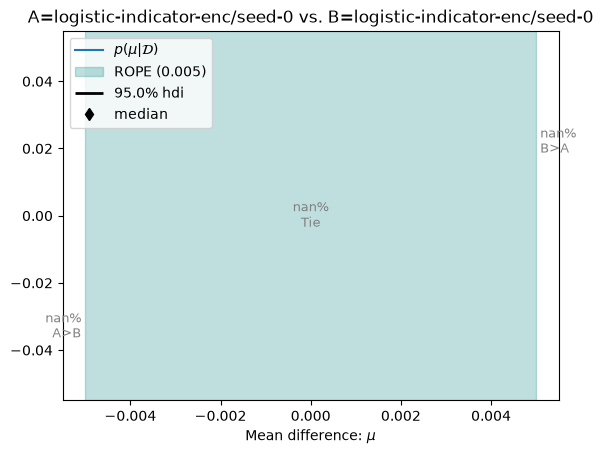

In [ ]:
# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

posterior = analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, 'logistic_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(my_classifiers, 'logistic_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    names=["logistic-indicator-enc/seed-0", "logistic-indicator-enc/seed-0"]
)
p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005)  # if you need to zoom in or out reduce/increase the argument rope_factor (it doesn't affect the ROPE, only the visualisation of it)